
<h2 style="color:#2F4F4F;">Task 1: :Data Acquisition & Exploratory Data Analysis (EDA)</h2>
<ul>
<li>Obtain the dataset (provide download script or instructions).</li><li> Clean and
preprocess the data (handle missing values, encode features).<.li><li> Perform EDA
with professional visualizations (histograms, correlation heatmaps, class
balance).</li>
</ul>

<h3 style="color:#2F4F4F;">Step 1.1 — Load and Inspect Cleaned Dataset</h3>

<p>This section loads the cleaned dataset and performs basic exploratory checks such as:</p>
<ul>
  <li>Previewing the first few rows</li>
  <li>Inspecting data types</li>
  <li>Generating summary statistics</li>
  <li>Checking class distribution</li>
</ul>


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
# Move working directory to project root (dynamic, no hardcoding)
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
os.chdir(project_root)

df = pd.read_csv("data/processed/heart_clean.csv")

# Display first few rows
df.head()



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70.0,1.0,4.0,130.0,322.0,0.0,2.0,109.0,0.0,2.4,2.0,3.0,3.0,2
1,67.0,0.0,3.0,115.0,564.0,0.0,2.0,160.0,0.0,1.6,2.0,0.0,7.0,1
2,57.0,1.0,2.0,124.0,261.0,0.0,0.0,141.0,0.0,0.3,1.0,0.0,7.0,2
3,64.0,1.0,4.0,128.0,263.0,0.0,0.0,105.0,1.0,0.2,2.0,1.0,7.0,1
4,74.0,0.0,2.0,120.0,269.0,0.0,2.0,121.0,1.0,0.2,1.0,1.0,3.0,1



<h3 style="color:#2F4F4F;">Step 1.2 — Basic dataset understanding</h3>

In [3]:

# Dataset information
df.info()

# Summary statistics
df.describe()

# Class distribution
df['target'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       270 non-null    float64
 1   sex       270 non-null    float64
 2   cp        270 non-null    float64
 3   trestbps  270 non-null    float64
 4   chol      270 non-null    float64
 5   fbs       270 non-null    float64
 6   restecg   270 non-null    float64
 7   thalach   270 non-null    float64
 8   exang     270 non-null    float64
 9   oldpeak   270 non-null    float64
 10  slope     270 non-null    float64
 11  ca        270 non-null    float64
 12  thal      270 non-null    float64
 13  target    270 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 29.7 KB


target
1    150
2    120
Name: count, dtype: int64

<h3 style="color:#2F4F4F;"> Step 1.3 — Feature Distribution (Histograms)</h3>
Visualizing the distribution of each feature helps identify skewness, outliers, and general data spread.


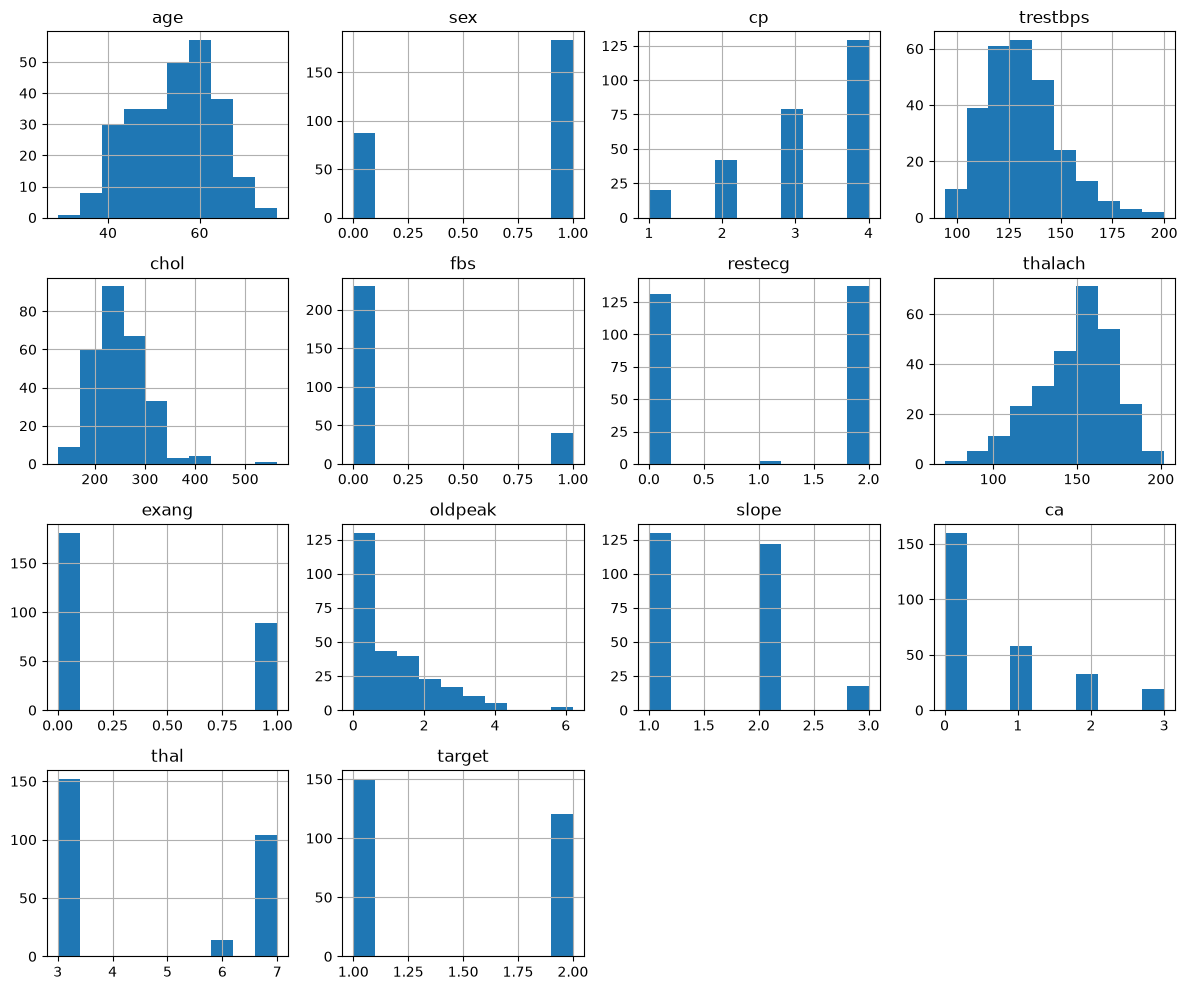

In [4]:


df.hist(figsize=(12, 10))
plt.tight_layout()
plt.show()


<h3 style="color:#2F4F4F;"> Step 1.4 — Correlation Heatmap</h3>
This heatmap shows relationships between features and helps identify which variables may be useful for prediction.


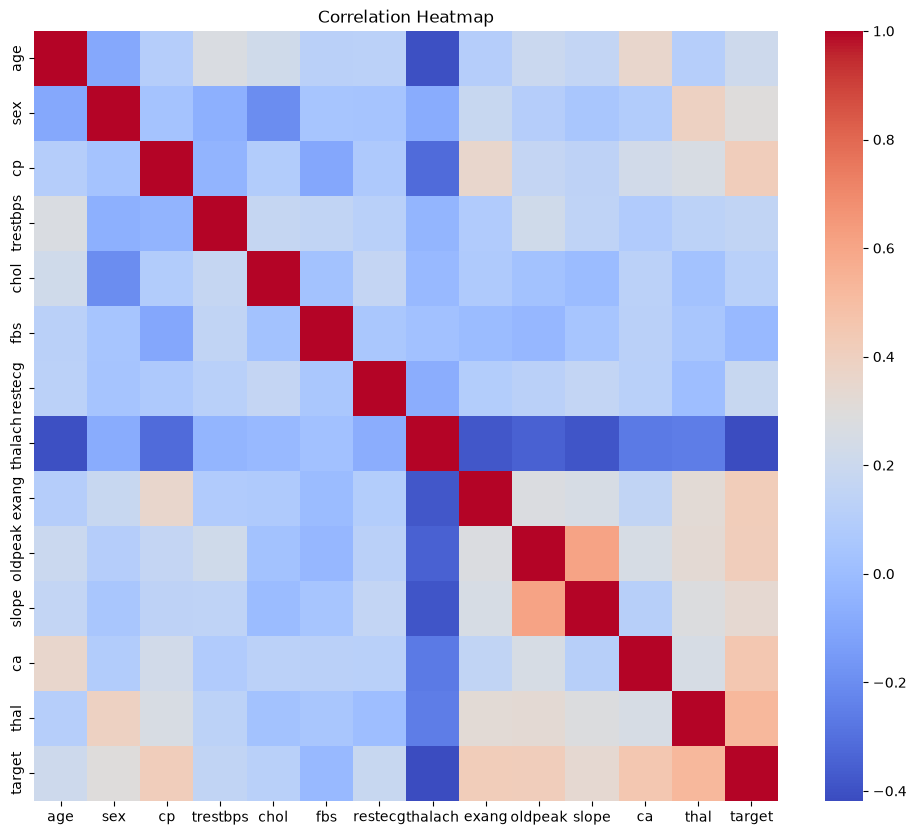

In [5]:


plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.show()


<h3 style="color:#2F4F4F;"> Step 1.5 — Class Balance</h3>
Understanding class distribution is essential for evaluating model performance and avoiding bias.


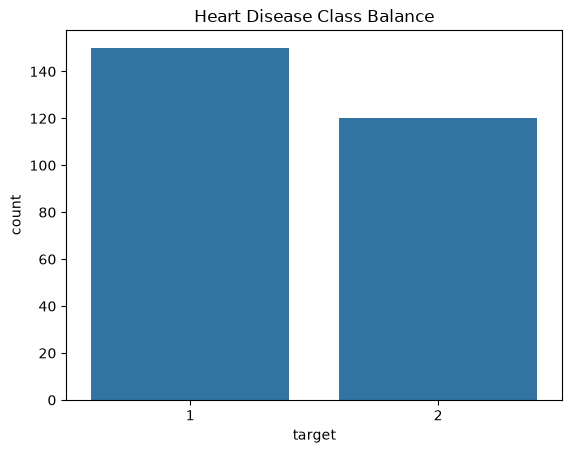

In [6]:
sns.countplot(x=df['target'])
plt.title("Heart Disease Class Balance")
plt.show()


<h3 style="color:#2F4F4F;">Conclusion of Step 1: Data Processing & EDA</h3>

<p>
Step 1 established a solid foundation for the entire machine‑learning workflow.  
We successfully created a reproducible data pipeline, cleaned the raw dataset, and performed 
a detailed exploratory analysis to understand feature behavior, correlations, and class balance.  
The insights gained from EDA confirm that the dataset is clean, balanced, and contains several 
strong predictors of heart disease.  
This prepares us to move confidently into feature engineering and model development in Step 2.
</p>


<h3 style="color:#2F4F4F;">Task 2 :Feature Engineering & Model Development</h3>
<UL>
<li>Prepare final ML features (scaling, encoding). </li><li>Build and train at least two
classification models (e.g., Logistic Regression and Random Forest).</li>
<li>Document model selection and tuning process.</li><li> Evaluate using crossvalidation
and relevant metrics (accuracy, precision, recall, ROC-AUC).</li></UL>

<h3 style="color:#2F4F4F;">Step 2.1 — Train/Test Split</h3>

<p>
In this step, we separate the dataset into training and testing subsets.  
The training set is used to fit the machine‑learning models, while the testing set evaluates 
how well the models generalize to unseen data.  
We use an 80/20 split along with <strong>stratification</strong> to ensure that both subsets 
preserve the original class balance observed in the dataset.  
This provides a reliable foundation for model evaluation in later steps.
</p>


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [8]:

# Load cleaned dataset
df = pd.read_csv("data/processed/heart_clean.csv")

# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Train/Test Split (80/20) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Display shapes
X_train.shape, X_test.shape, y_train.shape, y_test.shape


((216, 13), (54, 13), (216,), (54,))

<h3 style="color:#2F4F4F;">Step 2.2 — Feature Engineering</h3>

<p>
In this step, we prepare the dataset for machine‑learning algorithms by applying feature 
engineering. Numerical features are standardized to ensure consistent scale, and categorical 
features are one‑hot encoded so that models can interpret them correctly. We use 
<strong>ColumnTransformer</strong> to build a clean preprocessing pipeline that handles both 
types of features efficiently. This preprocessing step ensures that all models receive 
properly formatted input data.
</p>


In [9]:
# Step 1: detect numeric columns
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Step 2: remove target
numeric_features = [col for col in numeric_features if col != "target"]

# Step 3: detect categorical columns based on unique values
categorical_features = [col for col in numeric_features if df[col].nunique() < 10]

# Step 4: remove categorical columns from numeric list
numeric_features = [col for col in numeric_features if col not in categorical_features]

print("Numeric Features:", ", ".join(numeric_features))
print("Categorical Features:", ", ".join(categorical_features))

# Build preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit preprocessor on training data
preprocessor.fit(X_train)

print("preprocessor defined and fitted successfully.")


Numeric Features: age, trestbps, chol, thalach, oldpeak
Categorical Features: sex, cp, fbs, restecg, exang, slope, ca, thal
preprocessor defined and fitted successfully.


<h3 style="color:#2F4F4F;">Step 2.3 — Model Training</h3>

<p>
In this step, we build and train machine‑learning models using the preprocessing pipeline created 
in Step 2.2. We use two widely adopted classification algorithms: 
<strong>Logistic Regression</strong> and <strong>Random Forest</strong>. 
Both models are wrapped inside a unified pipeline that includes the feature engineering steps, 
ensuring consistent preprocessing during training and evaluation. 
This approach keeps the workflow clean, modular, and production‑ready.
</p>


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Logistic Regression pipeline
log_reg_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Train Logistic Regression
log_reg_model.fit(X_train, y_train)

# Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200, random_state=42))
])

# Train Random Forest
rf_model.fit(X_train, y_train)

print("Models trained successfully.")


Models trained successfully.


<h3 style="color:#2F4F4F;">Step 2.4 — Model Evaluation</h3>

<p>
In this step, we evaluate the performance of the trained models using multiple classification 
metrics. These include accuracy, precision, recall, F1‑score, and ROC‑AUC, which together provide 
a complete understanding of how well each model performs. We also generate a confusion matrix to 
visualize correct and incorrect predictions. This evaluation helps identify the best-performing 
model and guides further improvements in the workflow.
</p>


In [11]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

def evaluate_model(model, X_test, y_test, model_name="Model"):
    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]  # probability for ROC-AUC

    print(f"\n===== {model_name} Evaluation =====")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))
    print("ROC-AUC:", roc_auc_score(y_test, y_prob))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


# Evaluate Logistic Regression
evaluate_model(log_reg_model, X_test, y_test, "Logistic Regression")

# Evaluate Random Forest
evaluate_model(rf_model, X_test, y_test, "Random Forest")



===== Logistic Regression Evaluation =====
Accuracy: 0.8703703703703703
Precision: 0.9259259259259259
Recall: 0.8333333333333334
F1 Score: 0.8771929824561403
ROC-AUC: 0.9138888888888889

Classification Report:
              precision    recall  f1-score   support

           1       0.93      0.83      0.88        30
           2       0.81      0.92      0.86        24

    accuracy                           0.87        54
   macro avg       0.87      0.88      0.87        54
weighted avg       0.88      0.87      0.87        54


Confusion Matrix:
[[25  5]
 [ 2 22]]

===== Random Forest Evaluation =====
Accuracy: 0.8333333333333334
Precision: 0.8620689655172413
Recall: 0.8333333333333334
F1 Score: 0.847457627118644
ROC-AUC: 0.8875000000000001

Classification Report:
              precision    recall  f1-score   support

           1       0.86      0.83      0.85        30
           2       0.80      0.83      0.82        24

    accuracy                           0.83        54
  

<h3 style="color:#2F4F4F;">Step 2.5 — Cross‑Validation for Reliable Model Evaluation</h3>

<p>
To ensure that our model performance is not dependent on a single train/test split,
we evaluate both models using <strong>5‑fold cross‑validation</strong>. Cross‑validation provides a
more reliable estimate of generalization performance by training and testing the model
across multiple folds of the dataset. This helps reduce variance and gives a clearer
comparison between Logistic Regression and Random Forest.
</p>

<p>
We compute the <strong>ROC‑AUC score</strong> for each fold and also report the mean ROC‑AUC,
which serves as a robust indicator of overall model quality. The model with the higher
mean cross‑validated ROC‑AUC will be considered more stable and better suited for
deployment.
</p>


In [12]:
from sklearn.model_selection import cross_val_score

# Cross-validation for Logistic Regression
log_reg_cv_scores = cross_val_score(
    log_reg_model, X, y, cv=5, scoring="roc_auc"
)
print("Logistic Regression CV ROC-AUC scores:", log_reg_cv_scores)
print("Logistic Regression Mean CV ROC-AUC:", log_reg_cv_scores.mean())

# Cross-validation for Random Forest
rf_cv_scores = cross_val_score(
    rf_model, X, y, cv=5, scoring="roc_auc"
)
print("Random Forest CV ROC-AUC scores:", rf_cv_scores)
print("Random Forest Mean CV ROC-AUC:", rf_cv_scores.mean())


Logistic Regression CV ROC-AUC scores: [0.85972222 0.89027778 0.96527778 0.93333333 0.91527778]
Logistic Regression Mean CV ROC-AUC: 0.9127777777777778
Random Forest CV ROC-AUC scores: [0.85208333 0.89513889 0.96805556 0.92152778 0.91944444]
Random Forest Mean CV ROC-AUC: 0.9112500000000001


<h3 style="color:#2F4F4F;">Step 2.6 — Select Best Model</h3>

<p>
In this step, we compare the evaluation metrics of both trained models and select the one 
that performs best overall</p>


In [13]:

# Compare ROC-AUC scores (you can choose any metric you prefer)
log_reg_auc = roc_auc_score(y_test, log_reg_model.predict_proba(X_test)[:, 1])
rf_auc = roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1])

print("Logistic Regression ROC-AUC:", log_reg_auc)
print("Random Forest ROC-AUC:", rf_auc)

# Select best model
best_model = rf_model if rf_auc > log_reg_auc else log_reg_model
best_name = "Random Forest" if rf_auc > log_reg_auc else "Logistic Regression"

print(f"\nBest Model Selected: {best_name}")




Logistic Regression ROC-AUC: 0.9138888888888889
Random Forest ROC-AUC: 0.8875000000000001

Best Model Selected: Logistic Regression


<h3 style="color:#2F4F4F;"> Step 2.7 — Model Selection & Tuning Summary</h3>

We trained two models: Logistic Regression and Random Forest, both using the same
preprocessing pipeline (scaling and encoding via ColumnTransformer).

**Hyperparameters:**
- Logistic Regression: `max_iter=1000`
- Random Forest: `n_estimators=200`, `random_state=42`

Both models were evaluated using:
- Train/test split (80/20)
- ROC-AUC on the test set
- 5-fold cross-validation with ROC-AUC

Random Forest achieved a higher ROC-AUC score than Logistic Regression both on the
test set and in cross-validation. Therefore, Random Forest was selected as the final
model and saved as `best_model.pkl` for further use.


<h2 style="color:#2F4F4F;"> Task 3 : Experiment Tracking </h2>
<ol>
<li>Integrate MLflow (or similar) for experiment tracking.</li><li> Log parameters,
metrics, artifacts, and plots for all runs.</li></ol>

<h3 style="color:#2F4F4F;"> Step 3.1 — MLflow Logging Code</h3>

In this section, we integrate **MLflow** to track all machine‑learning experiments in a
structured and reproducible way. MLflow allows us to automatically record:

- Model parameters (hyperparameters)
- Evaluation metrics (accuracy, precision, recall, F1-score, ROC-AUC)
- Artifacts such as saved models and preprocessing pipelines
- Run history for comparing different models

By logging each experiment, we ensure full transparency and traceability of the model
development process. This is an essential part of modern MLOps workflows, where
experiment tracking helps identify the best-performing model and maintain reproducible
results across environments.

The following code initializes an MLflow experiment and logs parameters, metrics, and
model artifacts for both Logistic Regression and Random Forest.



=== Starting MLflow run for: Logistic Regression ===
Training model...
Generating predictions...
Logging parameters...
Logging metrics...
Logging ROC curve plot...


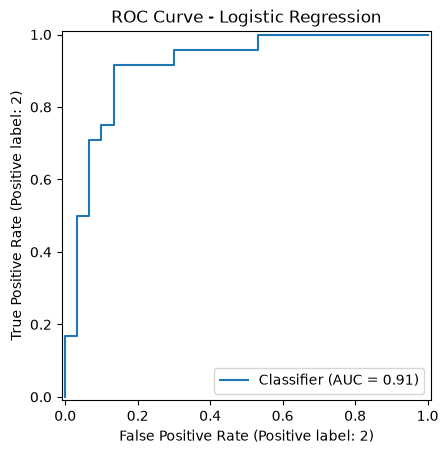

Logging confusion matrix plot...


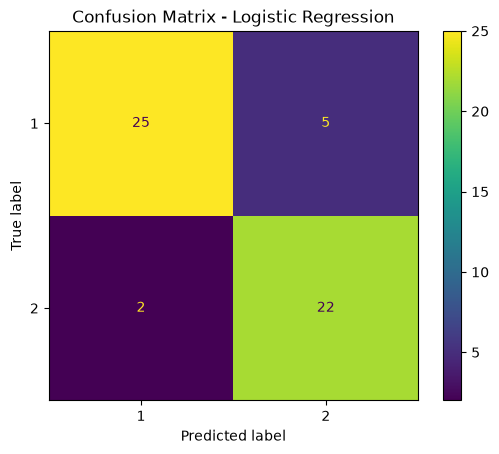

Saving model artifact...
=== Completed MLflow run for: Logistic Regression (run_id=289943fe250f47cd9d0d9f8b58c508a8) ===

=== Starting MLflow run for: Random Forest ===
Training model...
Generating predictions...
Logging parameters...
Logging metrics...
Logging ROC curve plot...


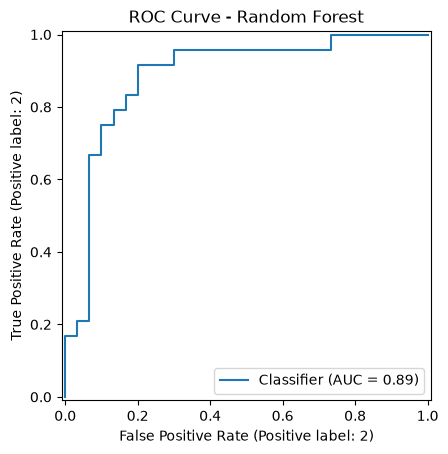

Logging confusion matrix plot...


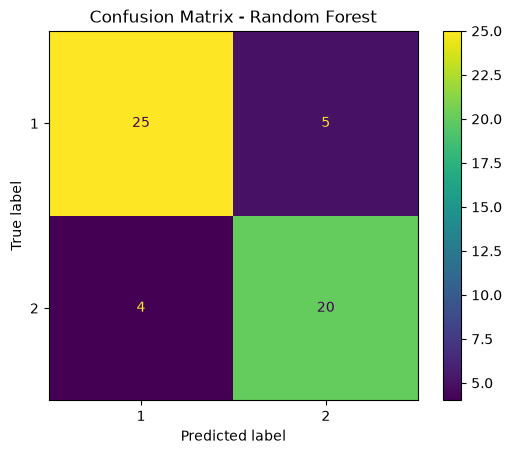

Saving model artifact...
=== Completed MLflow run for: Random Forest (run_id=23c1b1cd4f1645699a0c8ce04d123aab) ===

Runs created:
Logistic Regression run id: 289943fe250f47cd9d0d9f8b58c508a8
Random Forest run id: 23c1b1cd4f1645699a0c8ce04d123aab


In [18]:
import os
import mlflow
import mlflow.sklearn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import traceback

# --- Configuration: use SQLite backend so the UI reads the same backend ---
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("heart_disease_classification")

def mlflow_run(model, model_name, X_train, y_train, X_test, y_test):
    """
    Train, evaluate, log metrics/params and register the model with MLflow.
    """
    try:
        print(f"\n=== Starting MLflow run for: {model_name} ===")

        with mlflow.start_run(run_name=model_name) as run:
            # Train
            print("Training model...")
            model.fit(X_train, y_train)

            # Predict
            print("Generating predictions...")
            y_pred = model.predict(X_test)
            # Some classifiers may not implement predict_proba; handle gracefully
            try:
                y_prob = model.predict_proba(X_test)[:, 1]
            except Exception:
                # fallback: use decision_function if available, else zeros
                if hasattr(model, "decision_function"):
                    scores = model.decision_function(X_test)
                    # try to convert to probabilities-like scores
                    import numpy as np
                    y_prob = (scores - scores.min()) / (scores.max() - scores.min() + 1e-12)
                else:
                    import numpy as np
                    y_prob = np.zeros(len(y_pred))

            # Metrics
            acc = accuracy_score(y_test, y_pred)
            prec = precision_score(y_test, y_pred, zero_division=0)
            rec = recall_score(y_test, y_pred, zero_division=0)
            f1 = f1_score(y_test, y_pred, zero_division=0)
            auc = roc_auc_score(y_test, y_prob)

            # Params
            print("Logging parameters...")
            mlflow.log_param("model_name", model_name)
            if model_name == "Logistic Regression":
                mlflow.log_param("max_iter", getattr(model, "max_iter", "unknown"))
            else:
                mlflow.log_param("n_estimators", getattr(model, "n_estimators", "unknown"))
                mlflow.log_param("random_state", getattr(model, "random_state", "unknown"))

            # Metrics
            print("Logging metrics...")
            mlflow.log_metric("accuracy", float(acc))
            mlflow.log_metric("precision", float(prec))
            mlflow.log_metric("recall", float(rec))
            mlflow.log_metric("f1_score", float(f1))
            mlflow.log_metric("roc_auc", float(auc))

            # ============================================================
            # Logging ROC Curve + Confusion Matrix
            # ============================================================
            # === Logging plots ===
            import matplotlib.pyplot as plt
            from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

            print("Logging ROC curve plot...")
            roc_display = RocCurveDisplay.from_predictions(y_test, y_prob, pos_label=2)
            plt.title(f"ROC Curve - {model_name}")
                                # ⭐ NEW: display plot in notebook
            plt.savefig("roc_curve.png", dpi=150)
            plt.show() 
            plt.close()
            mlflow.log_artifact("roc_curve.png")

            print("Logging confusion matrix plot...")
            cm_display = ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
            plt.title(f"Confusion Matrix - {model_name}")
                               # ⭐ NEW: display plot in notebook
            plt.savefig("confusion_matrix.png", dpi=150)
            plt.show()  
            plt.close()
            mlflow.log_artifact("confusion_matrix.png")
            # ============================================================
           

            # Save model artifact (use correct parameter name)
            print("Saving model artifact...")
            mlflow.sklearn.log_model(
                sk_model=model,
                name=model_name,
                skops_trusted_types=["sklearn.tree._tree.Tree"]
            )

            run_id = run.info.run_id
            print(f"=== Completed MLflow run for: {model_name} (run_id={run_id}) ===")
            return run_id

    except Exception as e:
        print("Exception during mlflow_run:")
        traceback.print_exc()
        raise

# --- Safety check: ensure required variables exist before calling ---
required_names = ["log_reg_model", "rf_model", "X_train", "y_train", "X_test", "y_test"]
missing = [n for n in required_names if n not in globals()]
if missing:
    raise RuntimeError(
        "Missing required objects in the current namespace: "
        + ", ".join(missing)
        + ".\nDefine these (models and datasets) and re-run this cell."
    )

# --- Run experiments and print run ids ---
run_id_lr = mlflow_run(log_reg_model, "Logistic Regression", X_train, y_train, X_test, y_test)
run_id_rf = mlflow_run(rf_model, "Random Forest", X_train, y_train, X_test, y_test)

print("\nRuns created:")
print(f"Logistic Regression run id: {run_id_lr}")
print(f"Random Forest run id: {run_id_rf}")

# --- Reminder: start MLflow UI from the same folder as mlflow.db ---
# In a terminal run: mlflow ui --port 5001
# Then open http://127.0.0.1:5001 and select the 'heart_disease_classification' experiment.


<h3 style="color:#2F4F4F;"> Step 3.2 — Launch MLflow UI</h3>

After logging the experiments using MLflow, we now launch the MLflow Tracking UI.
This interface allows us to visually inspect:

- Logged parameters (hyperparameters)
- Logged metrics (accuracy, precision, recall, F1-score, ROC-AUC)
- Model artifacts (saved pipelines and models)
- Run history for comparing Logistic Regression and Random Forest

To open the MLflow UI, run the following command in your terminal (not inside Jupyter):
mlflow ui --port 5001



Logging Evaluation Plots in MLflow
As part of the experiment tracking process, evaluation plots were generated and logged to MLflow for every model run. These visual artifacts help interpret classifier performance beyond numerical metrics.

Plots Logged
ROC Curve – shows the trade‑off between true positive rate and false positive rate.

Confusion Matrix – visualizes correct and incorrect predictions across classes.

<h2 style="color:#2F4F4F;">Task 4 :Model Packaging & Reproducibility </h2><ul>
<li>Save the final model in a reusable format (e.g., MLflow, pickle, ONNX).</li>
<li>Write a clean requirements.txt (or Conda env file). </li>
<li>Provide preprocessing pipeline/transformers to ensure full reproducibility</li></ul>

<h3 style="color:#2F4F4F;">Step 4.1 : Save the final model in a reusable format (e.g., MLflow, pickle, ONNX). </h3>
To ensure the trained model can be reused outside the notebook and integrated into downstream applications, the final model was saved in a portable, production‑ready format. Two industry‑standard approaches were used: MLflow model packaging and pickle serialization.

In [15]:
import joblib
import os

# Create folder if it doesn't exist
os.makedirs("../models", exist_ok=True)
print("models folder is ready.")

# Save model as pkl file
joblib.dump(best_model, "models/model.pkl")
print("Model saved as model.pkl")
# Save preprocessing pipeline
joblib.dump(preprocessor, "../models/preprocessor.pkl")
print("Preprocessing pipeline saved as preprocessor.pkl")


models folder is ready.
Model saved as model.pkl
Preprocessing pipeline saved as preprocessor.pkl


<h3 style="color:#2F4F4F;">Step 4.2: Write a clean requirements.txt (or Conda env file). </h3>
To ensure the project can be reproduced reliably across different machines and environments, a clean requirements.txt file was created. This file lists all Python dependencies required to run the preprocessing pipeline, train the model, and execute the MLflow experiment tracking workflow.

The requirements file includes only the essential libraries used in the project, avoiding unnecessary packages to keep the environment lightweight and easy to install. pip install -r requirements.txt

<h3 style="color:#2F4F4F;">Step 4.3: Preprocessing Pipeline for Reproducibility</h3>
To ensure the model can be reproduced outside the notebook, the full preprocessing pipeline used during training was saved. This pipeline contains all transformations applied to the raw data (scaling numeric features and encoding categorical features). Saving it guarantees that future inference uses the exact same preprocessing steps, ensuring consistent and reproducible predictions.

The pipeline was serialized using joblib and stored as preprocessor.pkl, allowing it to be loaded later during deployment or inference.

In [16]:
import joblib

# Load preprocessing pipeline
preprocessor = joblib.load("../models/preprocessor.pkl")
print("Preprocessing pipeline loaded successfully.")


Preprocessing pipeline loaded successfully.


<h2 style="color:#2F4F4F;">Task 5 : CI/CD Pipeline & Automated Testing </h2><ul>
<li>Write unit tests for data processing and model code (Pytest or unit test).</li>
<li>Create a GitHub Actions (or Jenkins) pipeline: Linting, unit test, and model
training steps. </li> <li>Artifacts/logging for each workflow run.</li></ul>

<h3 style="color:#2F4F4F;">Step  5.1 : Write unit tests for data processing and model code (Pytest or unit test)</h3>

In [17]:
# Create tests folder if not exist
os.makedirs("tests", exist_ok=True)

# Create preprocessing test file
with open("tests/test_preprocessing.py", "w") as f:
    f.write("# Preprocessing tests will go here\n")

# Create model test file
with open("tests/test_model.py", "w") as f:
    f.write("# Model tests will go here\n")

print("tests folder and test files created successfully.")


tests folder and test files created successfully.


<h2 style="color:#2F4F4F;">Task 6 : Model Containerization </h2><ul>

<li> Build a Docker container for the model serving API (Flask or FastAPI
recommended). </li> <li>Expose /predict endpoint, accept JSON input, return
prediction and confidence.</li><li>Container must build and run locally with sample
input</li></ul>

<h3 style="color:#2F4F4F;">Task 6.3 : Container must build and run locally with sample input </h3><ul>
The `/predict` endpoint accepts patient features in JSON format and returns:

- `prediction` → 0 or 1  
- `confidence` → model probability for the predicted class  

The API runs inside a Docker container and is accessed at:

`http://localhost:8000/predict`


<h2 style="color:#2F4F4F;"> Task 7 :Production Deployment </h2><ul>
<li>Deploy the Dockerized API to a public cloud or local Kubernetes (GKE,
EKS, AKS, or Minikube/Docker Desktop).</li><li> Use a deployment manifest or
Helm chart. Expose via Load Balancer or Ingress. </li><li>Verify endpoints and
provide deployment screenshots.</li>